# 1D Diffusion Equation: Implicit BTCS Scheme

## 1. Theory & Stability Analysis
The Backward Time Centered Space (BTCS) scheme evaluates the spatial derivative at $t_{n+1}$:
$$-C \rho_{i-1}^{n+1} + (1 + 2C) \rho_i^{n+1} - C \rho_{i+1}^{n+1} = \rho_i^n, \quad C = \frac{D \Delta t}{\Delta x^2}$$

**von Neumann Stability:**
$$G(k) = \frac{1}{1 + 4 C \sin^2(k \Delta x / 2)} \le 1 \quad \forall \Delta t > 0$$
The BTCS scheme is **unconditionally stable**.

## 2. EXACT CODE FROM QUIZ 2 REFERENCE PDF (Section 2.3)
Implicit BTCS tridiagonal matrix solver using `scipy.linalg.solve` with $C = 2.22 \gg 0.5$.

Implicit BTCS Courant number C = 2.222 (Unconditionally stable)


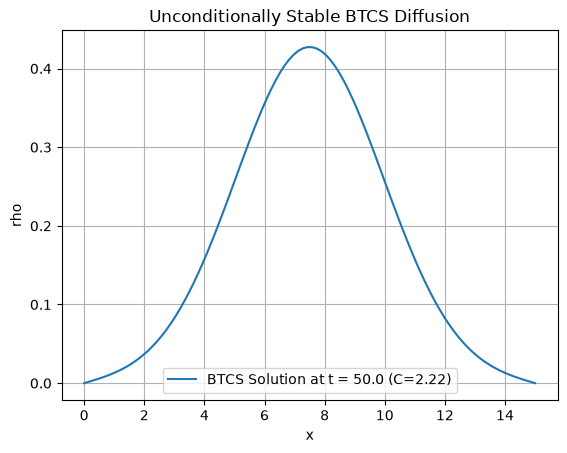

In [ ]:
import numpy as np
import scipy.linalg as la
import matplotlib.pyplot as plt

N = 100
dx = 0.15
L = N * dx
D = 0.05
dt = 1.0              # Deliberately large time step (C = 2.22 >> 0.5, FTCS would blow up!)
C = D * dt / (dx**2)
print(f"Implicit BTCS Courant number C = {C:.3f} (Unconditionally stable)")

x = np.linspace(0, L, N)
rho = np.exp(-((x - L/2) / 1.5)**2)

# Build Tridiagonal Matrix A
main_diag = (1 + 2 * C) * np.ones(N)
off_diag = -C * np.ones(N - 1)
A = np.diag(main_diag) + np.diag(off_diag, -1) + np.diag(off_diag, 1)

# Apply Dirichlet BCs on matrix A: rho[0] = 0, rho[N-1] = 0
A[0, :] = 0; A[0, 0] = 1.0 
A[-1, :] = 0; A[-1, -1] = 1.0

# Time integration
for step in range(50):
    rhs = rho.copy()
    rhs[0] = 0.0
    rhs[-1] = 0.0
    rho = la.solve(A, rhs)

plt.plot(x, rho, label=f'BTCS Solution at t = {50*dt:.1f} (C={C:.2f})')
plt.title('Unconditionally Stable BTCS Diffusion')
plt.xlabel('x'); plt.ylabel('rho'); plt.legend(); plt.grid(True); plt.show()


## 3. PROBLEM SET III Q5: Explicit vs. Implicit Stability Comparison
Running FTCS and BTCS with the same timestep violating FTCS stability ($C = 0.60 > 0.5$).

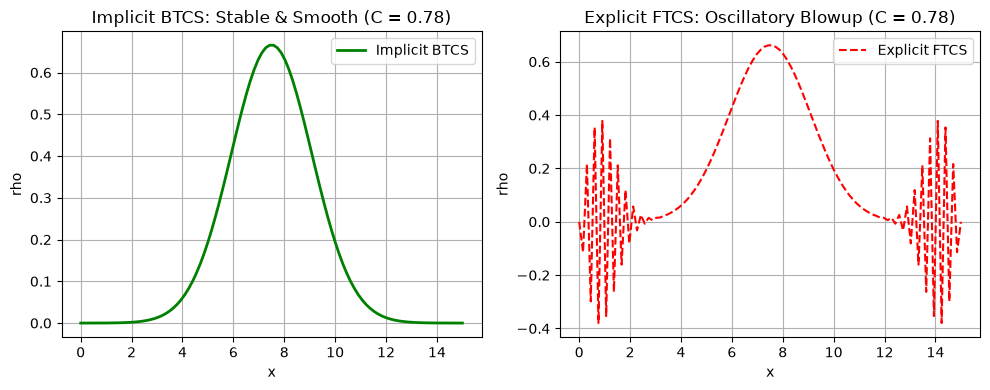

In [13]:
dt_comp = 0.35
C_comp = D * dt_comp / (dx**2) # C ≈ 0.60 > 0.5

# Initialize identical profiles
rho_init = np.exp(-((x - L/2) / 1.5)**2)
rho_ftcs = rho_init.copy()
rho_btcs = rho_init.copy()

# Matrix for BTCS
A_comp = np.diag((1 + 2*C_comp)*np.ones(N)) + np.diag(-C_comp*np.ones(N-1), -1) + np.diag(-C_comp*np.ones(N-1), 1)
A_comp[0, :] = 0; A_comp[0, 0] = 1
A_comp[-1, :] = 0; A_comp[-1, -1] = 1

# Advance 12 steps
for _ in range(40):
    # FTCS update
    rho_ftcs_new = rho_ftcs.copy()
    rho_ftcs_new[1:-1] = rho_ftcs[1:-1] + C_comp * (rho_ftcs[2:] + rho_ftcs[:-2] - 2*rho_ftcs[1:-1])
    rho_ftcs_new[0] = 0; rho_ftcs_new[-1] = 0
    rho_ftcs = rho_ftcs_new
    
    # BTCS update
    rhs = rho_btcs.copy(); rhs[0] = 0; rhs[-1] = 0
    rho_btcs = la.solve(A_comp, rhs)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(x, rho_btcs, 'g-', lw=2, label='Implicit BTCS')
plt.title(f'Implicit BTCS: Stable & Smooth (C = {C_comp:.2f})')
plt.xlabel('x'); plt.ylabel('rho'); plt.legend(); plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(x, rho_ftcs, 'r--', lw=1.5, label='Explicit FTCS')
plt.title(f'Explicit FTCS: Oscillatory Blowup (C = {C_comp:.2f})')
plt.xlabel('x'); plt.ylabel('rho'); plt.legend(); plt.grid(True)
plt.tight_layout()
plt.show()